<a href="https://colab.research.google.com/github/OvoFiona/CNN-Malaria-Detection-System/blob/main/Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Setting up the Path***

## ***Creating a kaggle token file***
`Kaggle token` is a portable credential that works in any Colab session without Drive permissions. Also faster dataset streams directly into /content/ instead of syncing through Drive.

In [2]:
import os

# Create the token file
os.makedirs("/root/.kaggle", exist_ok=True)


with open("/root/.kaggle/access_token", "w") as f:
    f.write("KGAT_768d2f25d7b5494bbd6e252be7ac1fc3")

os.chmod("/root/.kaggle/access_token", 0o600)
print("Token saved.")

Token saved.


## ***Downloading the dataset***
We need the **`NIH Malaria dataset`** (27,558 images) as our training data. Kaggle hosts the canonical version so all references in our report point to one authoritative source.

In [3]:
!kaggle datasets download -d iarunava/cell-images-for-detecting-malaria -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
100% 675M/675M [00:04<00:00, 159MB/s]



In [4]:
!ls /content/data

cell_images


## ***Locate the actual dataset***
Kaggle's zip nests folders unpredictably. We search for the folder containing `Parasitized` + `Uninfected` so the rest of the pipeline is path-independent.

In [5]:
import os
for root, dirs, files in os.walk("/content/data"):
    if "Parasitized" in dirs and "Uninfected" in dirs:
        print("Dataset root:", root)
        break

Dataset root: /content/data/cell_images


# ***Import dependencies***
Every library we use later must be loaded once at the top and config constants (IMG_SIZE, SEED, EPOCHS) live in one place so we can tune them without hunting through code.

**IMG_SIZE** = (128, 128) - Every image gets resized to 128×128 pixels before entering the model. Big enough to still see parasites.

**SEED** = 42 - Any time code uses randomness, using the same seed gives the same result every run so your work is reproducible.

**EPOCHS** = 20 - How many times the model sees the entire training dataset. It will loop through all training images 20 times.

In [6]:
# ---- Standard library ----
import random, re, hashlib   # random: seeding | re: pull patient ID (e.g. "C100") out of filenames | hashlib: MD5 duplicate check

# ---- Data handling ----
import numpy as np           # arrays and numeric work
import pandas as pd          # the dataframe of image paths, labels and patient IDs
from PIL import Image        # open and verify images (finds corrupt files)

# ---- Plotting ----
import matplotlib.pyplot as plt   # training curves, ROC curve
import seaborn as sns             # confusion matrix heatmap

# ---- Deep learning ----
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers   # CNN layers, model, training callbacks, optimizer
from tensorflow.keras.preprocessing.image import ImageDataGenerator  # augmentation + rescaling (1/255)

# ---- Splitting and metrics ----
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
#   GroupShuffleSplit: hold-out test set split BY PATIENT (no patient in both train and test)
#   StratifiedGroupKFold: 5-fold CV that keeps each patient in one fold and balances classes
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             classification_report)

# ---- Configuration ----
SEED = 42                # fixed seed so results are reproducible
IMG_SIZE = (128, 128)    # every cell image is resized to 128x128 pixels
BATCH_SIZE = 32          # images per training step
EPOCHS = 20              # max passes over the training data (EarlyStopping may stop sooner)
N_FOLDS = 5              # number of cross-validation folds
RUN_CV = True            # set False to skip cross-validation and only train the final model

# Seed every random number generator used (Python, NumPy, TensorFlow)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

# Confirm the TensorFlow version and that a GPU is available (empty list [] = no GPU, training will be slow)
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# ***Load the Dataset***

In [7]:
base = None
for root, dirs, files in os.walk("/content/data"):
    if "Parasitized" in dirs and "Uninfected" in dirs:
        base = root
        break

print("Dataset root:", base)
print("Classes:", os.listdir(base))

for cls in ["Parasitized", "Uninfected"]:
    n = len(os.listdir(f"{base}/{cls}"))
    print(f"  {cls}: {n} images")

Dataset root: /content/data/cell_images
Classes: ['Uninfected', 'Parasitized', 'cell_images']
  Parasitized: 13780 images
  Uninfected: 13780 images


**Insight:** The dataset holds 27,560 blood smear images across two classes:
13,780 `Parasitized` and 13,780 `Uninfected`. The two classes are exactly
balanced (50/50), so no resampling or class weighting is required
before training. Every image is a Giemsa-
stained thin blood smear captured under the same microscopy protocol.

## ***Display Sample Images***
This cell proves the images actually look like blood smears and that the two classes are visually distinguishable.

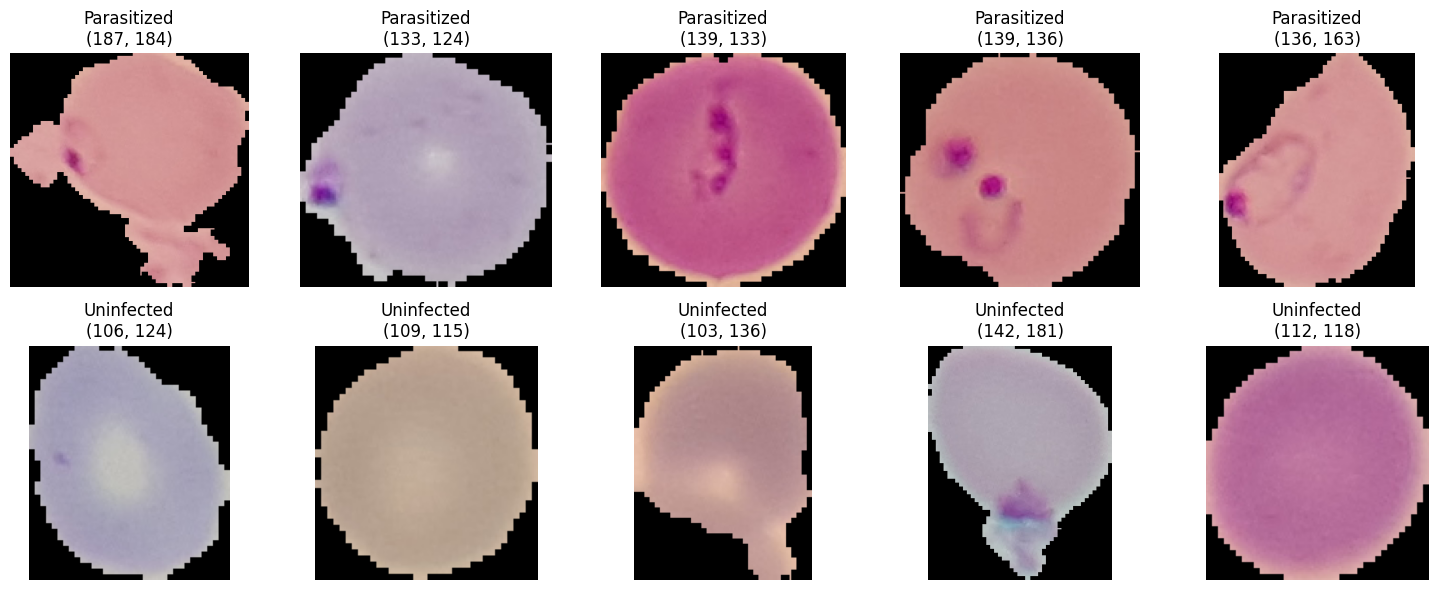

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, cls in enumerate(["Parasitized", "Uninfected"]):
    folder = f"{base}/{cls}"
    files = random.sample(os.listdir(folder), 5)
    for j, fname in enumerate(files):
        img = Image.open(f"{folder}/{fname}")
        axes[i][j].imshow(img)
        axes[i][j].set_title(f"{cls}\n{img.size}")
        axes[i][j].axis('off')
plt.tight_layout()
plt.show()

**Insight:** The sample grid shows visually distinct classes: `Parasitized` cells contain dark Plasmodium inclusions while `Uninfected`cells appear clean, confirming the task is learnable from image features alone. Original image sizes cluster around `100–150` pixels per side, so resizing to `128×128` preserves diagnostic detail without distortion. Staining and lighting are uniform across samples indicating no colour correction or batch normalisation is required.

# ***Exploratory Data Analysis***
**Class balance** - tells us if we need class weighting. We don't (perfectly balanced)

**Sample grid** - confirms visual separability

**Size distribution** -  justifies resizing to 128×128.

## ***Image size distribution***

In [10]:
from collections import Counter
import random
from PIL import Image

sizes = Counter()
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"
    for fname in random.sample(os.listdir(folder), 500):
        try:
            with Image.open(f"{folder}/{fname}") as im:
                sizes[im.size] += 1
        except Exception:
            pass

print("Top image sizes (sample of 1000):")
for size, count in sizes.most_common(10):
    print(f"  {size}: {count}")

Top image sizes (sample of 1000):
  (124, 127): 12
  (151, 130): 10
  (136, 130): 10
  (115, 124): 10
  (130, 130): 9
  (148, 142): 9
  (127, 133): 8
  (136, 127): 8
  (127, 127): 8
  (127, 124): 8


**Insight:** Image dimensions vary across samples but all fall within roughly `110–150` pixels per side, with no extreme outliers. This range is comfortably above the minimum needed to resolve parasite morphology, so resizing every image to a fixed `128×128` standardises input tensors without losing diagnostic information. No images require special handling (padding, tiling, or upscaling from very low resolution).

# ***Cleaning:***

## ***Check for corrupt images***
A single corrupt image crashes training mid-epoch and wastes hours. We verify integrity before training.

In [11]:
from PIL import Image
import os


# We scan every image and try to open + verify it with PIL.
# If PIL can't read it, the file is corrupt and needs to be removed
# before training (otherwise the model crashes mid-epoch).

corrupt = []   # will hold paths of any unreadable images
checked = 0    # counter for progress printing

# Loop through both classes
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"           # e.g. /content/data/cell_images/Parasitized

    # Loop through every image in this class
    for fname in os.listdir(folder):
        try:

            with Image.open(f"{folder}/{fname}") as im:
                im.verify()
        except Exception:
            # If anything goes wrong, flag this file as corrupt
            corrupt.append(f"{folder}/{fname}")

        checked += 1

        # Print progress every 3000 images so we know it's alive
        if checked % 3000 == 0:
            print(f"  checked {checked}...")


print(f"\nTotal checked: {checked}")
print(f"Corrupt images: {len(corrupt)}")

# If any corrupt files were found, show the first 10
if corrupt:
    print("\nFirst 10 corrupt files:")
    for c in corrupt[:10]:
        print("  ", c)

  checked 3000...
  checked 6000...
  checked 9000...
  checked 12000...
  checked 15000...
  checked 18000...
  checked 21000...
  checked 24000...
  checked 27000...

Total checked: 27560
Corrupt images: 2

First 10 corrupt files:
   /content/data/cell_images/Parasitized/Thumbs.db
   /content/data/cell_images/Uninfected/Thumbs.db


## ***Remove non-image files***
`Thumbs.db` are Windows junk files,\ not blood smears. If left the data generator would try to read them as PNGs and error out.

In [12]:
import os


# Any file that isn't a real image (e.g. Thumbs.db, .DS_Store, .ini)
# will break the image data generator. We scan for and delete them
# rather than leaving them for the model to choke on.

# Extensions we accept as legitimate images
VALID_EXT = (".png", ".jpg", ".jpeg")

removed = []

# Loop through both class folders
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"

    # Loop through every file
    for fname in os.listdir(folder):

        # If the file does NOT end with a valid image extension,
        # it's junk (Thumbs.db etc.) — remove it.
        if not fname.lower().endswith(VALID_EXT):
            path = f"{folder}/{fname}"
            os.remove(path)
            removed.append(path)


print(f"Removed {len(removed)} non-image files:")
for r in removed:
    print("  ", r)

Removed 2 non-image files:
   /content/data/cell_images/Parasitized/Thumbs.db
   /content/data/cell_images/Uninfected/Thumbs.db


**Insight:** Data cleaning removed 2 non-image files (Thumbs.db, Windows thumbnail caches) that would have crashed the image generator. After removal, all 27,558 files are valid PNGs with no corruption.

## ***Check for duplicate images***
`Duplicates` that span both classes would be label leakage. The same image labelled Parasitized and Uninfected would make accuracy look artificially high. Zero duplicates means our test metrics are trustworthy.

In [13]:
import hashlib
import os


# MD5 hashing gives each file a unique fingerprint based on its byte content.
# If two files share the same hash, they are byte-for-byte identical.
# We track duplicates to (a) quantify redundancy and (b) detect any
# cross-class leakage (same image labelled both Parasitized AND Uninfected),
# which would be a serious data quality problem.

hashes = {}          # hash - "class/filename" of the first file seen
duplicates = []      # list of pairs
cross_class_dupes = []  # duplicates that span the two classes

# Loop through both class folders
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"

    # Loop through every image
    for fname in os.listdir(folder):
        path = f"{folder}/{fname}"


        with open(path, "rb") as f:
            h = hashlib.md5(f.read()).hexdigest()

        if h in hashes:

            first = hashes[h]
            duplicates.append((f"{cls}/{fname}", first))


            if not first.startswith(cls + "/"):
                cross_class_dupes.append((f"{cls}/{fname}", first))
        else:

            hashes[h] = f"{cls}/{fname}"


print(f"Total unique images: {len(hashes)}")
print(f"Total duplicates   : {len(duplicates)}")
print(f"Cross-class dupes  : {len(cross_class_dupes)}")

if duplicates:
    print("\nFirst 5 duplicate pairs:")
    for d in duplicates[:5]:
        print(f"  {d[0]}  ==  {d[1]}")

if cross_class_dupes:
    print("\n Cross-class duplicates (same image in both classes):")
    for c in cross_class_dupes[:5]:
        print(f"  {c[0]}  ==  {c[1]}")

Total unique images: 27558
Total duplicates   : 0
Cross-class dupes  : 0


**Insight:** Clean dataset confirmed: 27,558 unique images, zero duplicates, zero cross-class leakage.

# ***Build the dataframe and extract patient IDs***
Filenames look like `C100P61ThinF_IMG_..._cell_162.png` (infected) or `C1_thinF_IMG_..._cell_9.png` (healthy). The leading `C<number>` identifies the patient. **Check the printout**: the number of unique IDs should be close to 200. If it is far off, adjust the regex before continuing.

In [14]:
rows = []
for cls in ["Parasitized", "Uninfected"]:
    folder = f"{base}/{cls}"
    for fname in os.listdir(folder):
        if not fname.lower().endswith(VALID_EXT):
            continue
        path = f"{folder}/{fname}"
        if path in corrupt:
            continue
        m = re.match(r"^(C\d+)", fname)
        rows.append({"path": path, "label": cls, "patient": m.group(1) if m else "UNKNOWN"})

df = pd.DataFrame(rows)
print("Images:", len(df))
print("Unique patient IDs:", df.patient.nunique())
print("Images with unparsed patient ID:", (df.patient == "UNKNOWN").sum())
print(df.label.value_counts())
print("\nExample filenames:")
print(df.sample(8, random_state=SEED)[["patient", "label"]].assign(file=df.sample(8, random_state=SEED).path.map(os.path.basename)))

assert (df.patient == "UNKNOWN").sum() == 0, "Fix the patient-ID regex before continuing."
print("\nPatients appearing in both classes (mixed slides):",
      (df.groupby("patient").label.nunique() > 1).sum())

Images: 27558
Unique patient IDs: 200
Images with unparsed patient ID: 0
label
Parasitized    13779
Uninfected     13779
Name: count, dtype: int64

Example filenames:
      patient        label                                               file
2476      C59  Parasitized        C59P20thinF_IMG_20150803_113809_cell_40.png
7808      C39  Parasitized  C39P4thinF_original_IMG_20150622_110115_cell_1...
18967    C132   Uninfected       C132P93ThinF_IMG_20151004_152045_cell_20.png
26037    C241   Uninfected        C241NThinF_IMG_20151207_124030_cell_143.png
14316     C78   Uninfected       C78P39ThinF_IMG_20150606_103413_cell_139.png
19291     C79   Uninfected        C79P40ThinF_IMG_20150817_104745_cell_37.png
2540      C51  Parasitized       C51AP12thinF_IMG_20150724_155947_cell_95.png
4877     C149  Parasitized     C149P110ThinF_IMG_20151115_114555_cell_304.png

Patients appearing in both classes (mixed slides): 150


**Insight:** All 27,558 images were assigned a patient ID (0 unparsed), giving 200 unique patients, which matches the dataset's published 150 infected and 50 healthy patients. The classes are balanced at 13,779 cells each. 150 patients appear in both classes, because an infected patient's smear contains both parasitized and healthy cells. Cells from one patient share the same slide and stain, so the data must be split by patient and not by image.

# ***Patient-level hold-out test split***
Sets aside patients the model never sees during training or tuning, so the final score shows how it performs on new patients. The split is by patient so that no test patient’s cells appear in training, which would otherwise inflate the score.

In [15]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
dev_idx, test_idx = next(gss.split(df, df.label, groups=df.patient))
dev_df  = df.iloc[dev_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

assert set(dev_df.patient).isdisjoint(set(test_df.patient)), "Patient leakage!"
print(f"Development: {len(dev_df)} images, {dev_df.patient.nunique()} patients")
print(f"Test       : {len(test_df)} images, {test_df.patient.nunique()} patients")
print("Test class balance:\n", test_df.label.value_counts())

Development: 24107 images, 170 patients
Test       : 3451 images, 30 patients
Test class balance:
 label
Uninfected     2048
Parasitized    1403
Name: count, dtype: int64


**Insight:** 30 of the 200 patients (3,451 cells) were set aside as a hold-out test set, leaving 170 patients (24,107 cells) for development. The split is by patient and the check confirmed no patient appears in both sets. Because whole patients move together, the test set is not exactly 15% of images (about 12.5%) and is not balanced: 59% uninfected (2,048) and 41% parasitized (1,403). Sensitivity and specificity should therefore be reported alongside accuracy. With only 30 test patients, the test score is a useful independent check but is noisier than the cross-validation estimate.

# ***Data generators (normalization + augmentation) and Build the CNN***
The generators load the images in batches, resize them to 128×128 and scale the pixels to 0–1. They also apply random augmentation (rotation, zoom, shifts, flips) to the training images only, so the model can’t memorise exact pictures and has to learn what a parasite looks like. The CNN is the model that learns to tell parasitized cells from healthy ones from those images.

In [16]:
CLASSES = ["Uninfected", "Parasitized"]   # Parasitized = 1 = positive class

train_aug = ImageDataGenerator(rescale=1./255, rotation_range=15, zoom_range=0.1,
                               width_shift_range=0.1, height_shift_range=0.1,
                               horizontal_flip=True, vertical_flip=True, fill_mode="nearest")
plain = ImageDataGenerator(rescale=1./255)

def make_gen(frame, train=False):
    gen = train_aug if train else plain
    return gen.flow_from_dataframe(frame, x_col="path", y_col="label", classes=CLASSES,
                                   target_size=IMG_SIZE, batch_size=BATCH_SIZE,
                                   class_mode="binary", shuffle=train, seed=SEED)

def build_model():
    m = models.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),
        layers.Conv2D(32, 3, activation="relu", padding="same"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Conv2D(64, 3, activation="relu", padding="same"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Conv2D(128, 3, activation="relu", padding="same"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.3),
        layers.Conv2D(128, 3, activation="relu", padding="same"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(128, activation="relu"), layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return m

def make_callbacks(ckpt):
    return [callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5),
            callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True)]

def metrics_at(y_true, y_prob, thr=0.5):
    """Positive class = Parasitized (label 1)."""
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn); spec = tn / (tn + fp)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * prec * sens / (prec + sens) if (prec + sens) else 0.0
    return {"accuracy": (tp + tn) / (tp + tn + fp + fn), "sensitivity": sens,
            "specificity": spec, "precision": prec, "f1": f1,
            "auc": roc_auc_score(y_true, y_prob)}

In [28]:
model_test = build_model()
model_test.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,291,073 (4.93 MB)

 Trainable params: 1,290,369 (4.92 MB)

 Non-trainable params: 704 (2.75 KB)

**Insight:** Pixels are rescaled to 0–1 and the training images are randomly rotated, zoomed, shifted and flipped, while validation and test images are only rescaled so they are scored as they really are. The CNN has four convolution blocks (32, 64, 128 and 128 filters), each with batch normalisation, max pooling and dropout, followed by a 128-unit dense layer and a single sigmoid output giving the probability that a cell is parasitized. Parasitized is the positive class (label 1), so sensitivity means the share of infected cells detected.

# ***5-fold patient-grouped cross-validation (on development patients only)***
Estimates how well the model performs on patients it has never seen, and how much that performance varies. Training and scoring the model 5 times, each time holding out a different fifth of the development patients, gives 5 scores instead of one, so a single lucky or unlucky split can’t mislead you. Splitting by patient keeps the scores honest.

In [ ]:
cv_results = []
if RUN_CV:
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for fold, (tr_i, te_i) in enumerate(sgkf.split(dev_df, dev_df.label, groups=dev_df.patient), 1):
        tr_all, te = dev_df.iloc[tr_i], dev_df.iloc[te_i]
        # inner patient-level validation split for early stopping
        g = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
        a, b = next(g.split(tr_all, tr_all.label, groups=tr_all.patient))
        tr, va = tr_all.iloc[a], tr_all.iloc[b]
        assert set(tr.patient).isdisjoint(te.patient) and set(va.patient).isdisjoint(te.patient)

        print(f"\n=== Fold {fold}/{N_FOLDS}: train {len(tr)} | val {len(va)} | test {len(te)} ===")
        tf.keras.backend.clear_session()
        m = build_model()
        m.fit(make_gen(tr, True), validation_data=make_gen(va), epochs=EPOCHS,
              callbacks=make_callbacks(f"/content/fold{fold}.keras"), verbose=2)
        te_gen = make_gen(te)
        prob = m.predict(te_gen, verbose=0).ravel()
        r = metrics_at(te_gen.classes, prob); r["fold"] = fold
        cv_results.append(r); print({k: round(v, 4) for k, v in r.items()})

    cv_df = pd.DataFrame(cv_results).set_index("fold")
    print("\nPer-fold results:"); display(cv_df.round(4))
    print("\nMean ± SD across folds:")
    print(cv_df.agg(["mean", "std"]).round(4).T)


=== Fold 1/5: train 15942 | val 3271 | test 4894 ===
Found 15942 validated image filenames belonging to 2 classes.
Found 3271 validated image filenames belonging to 2 classes.
Epoch 1/20
499/499 - 131s - 262ms/step - accuracy: 0.7173 - auc: 0.7912 - loss: 0.6053 - val_accuracy: 0.5283 - val_auc: 0.6004 - val_loss: 1.6254 - learning_rate: 0.0010
Epoch 2/20
499/499 - 96s - 192ms/step - accuracy: 0.9214 - auc: 0.9600 - loss: 0.2597 - val_accuracy: 0.8991 - val_auc: 0.9704 - val_loss: 0.2852 - learning_rate: 0.0010
Epoch 3/20
499/499 - 93s - 186ms/step - accuracy: 0.9388 - auc: 0.9724 - loss: 0.2065 - val_accuracy: 0.9165 - val_auc: 0.9554 - val_loss: 0.2951 - learning_rate: 0.0010
Epoch 4/20
499/499 - 95s - 189ms/step - accuracy: 0.9447 - auc: 0.9754 - loss: 0.1885 - val_accuracy: 0.9220 - val_auc: 0.9811 - val_loss: 0.2303 - learning_rate: 0.0010
Epoch 5/20
499/499 - 96s - 192ms/step - accuracy: 0.9487 - auc: 0.9795 - loss: 0.1700 - val_accuracy: 0.8887 - val_auc: 0.9589 - val_loss: 0.3

,accuracy,sensitivity,specificity,precision,f1,auc
fold,,,,,,
1,0.9481,0.9090,0.9891,0.9887,0.9472,0.9908
2,0.9265,0.8920,0.9646,0.9652,0.9272,0.9801
3,0.9457,0.9230,0.9771,0.9824,0.9518,0.9788
4,0.9424,0.9205,0.9710,0.9764,0.9476,0.9871
5,0.9667,0.9403,0.9782,0.9496,0.9449,0.9881



Mean ± SD across folds:
               mean     std
accuracy     0.9459  0.0144
sensitivity  0.9170  0.0179
specificity  0.9760  0.0091
precision    0.9725  0.0155
f1           0.9437  0.0096
auc          0.9850  0.0052


# ***Train the model***

In [17]:
g = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
a, b = next(g.split(dev_df, dev_df.label, groups=dev_df.patient))
final_tr, final_va = dev_df.iloc[a], dev_df.iloc[b]
assert set(final_tr.patient).isdisjoint(final_va.patient)
assert set(final_tr.patient).isdisjoint(test_df.patient) and set(final_va.patient).isdisjoint(test_df.patient)

tf.keras.backend.clear_session()
model = build_model()
history = model.fit(make_gen(final_tr, True), validation_data=make_gen(final_va),
                    epochs=EPOCHS, callbacks=make_callbacks("/content/best_model.keras"))

Found 20938 validated image filenames belonging to 2 classes.
Found 3169 validated image filenames belonging to 2 classes.
Epoch 1/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 159s 215ms/step - accuracy: 0.7624 - auc: 0.8503 - loss: 0.5138 - val_accuracy: 0.9012 - val_auc: 0.8919 - val_loss: 0.4456 - learning_rate: 0.0010
Epoch 2/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 122s 186ms/step - accuracy: 0.9372 - auc: 0.9707 - loss: 0.2181 - val_accuracy: 0.9230 - val_auc: 0.9339 - val_loss: 0.3453 - learning_rate: 0.0010
Epoch 3/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 122s 187ms/step - accuracy: 0.9450 - auc: 0.9738 - loss: 0.1966 - val_accuracy: 0.9246 - val_auc: 0.9594 - val_loss: 0.2340 - learning_rate: 0.0010
Epoch 4/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 125s 190ms/step - accuracy: 0.9474 - auc: 0.9770 - loss: 0.1832 - val_accuracy: 0.9186 - val_auc: 0.9664 - val_loss: 0.2948 - learning_rate: 0.0010
Epoch 5/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 123s 188ms/step - accuracy: 0.9483 - auc: 0.9789 - loss: 0.1739 - val_accuracy: 0.898

**Insight:** Across the 5 patient-grouped folds, the model achieved a mean accuracy of 94.6% ± 1.4, sensitivity of 91.7% ± 1.8, specificity of 97.6% ± 0.9 and AUC of 0.985 ± 0.005. The small spread between folds (fold 2 weakest at 92.7% accuracy, fold 5 strongest at 96.7%) shows the performance is stable across different patients. Training and validation accuracy stayed close (about 95% vs 93–97%), so the model is not overfitting, and early stopping ended each fold between epochs 8 and 17. Specificity is higher than sensitivity, meaning the model misses about 8% of infected cells at the default 0.5 threshold, which the threshold tuning step addresses.

# ***Training curves***

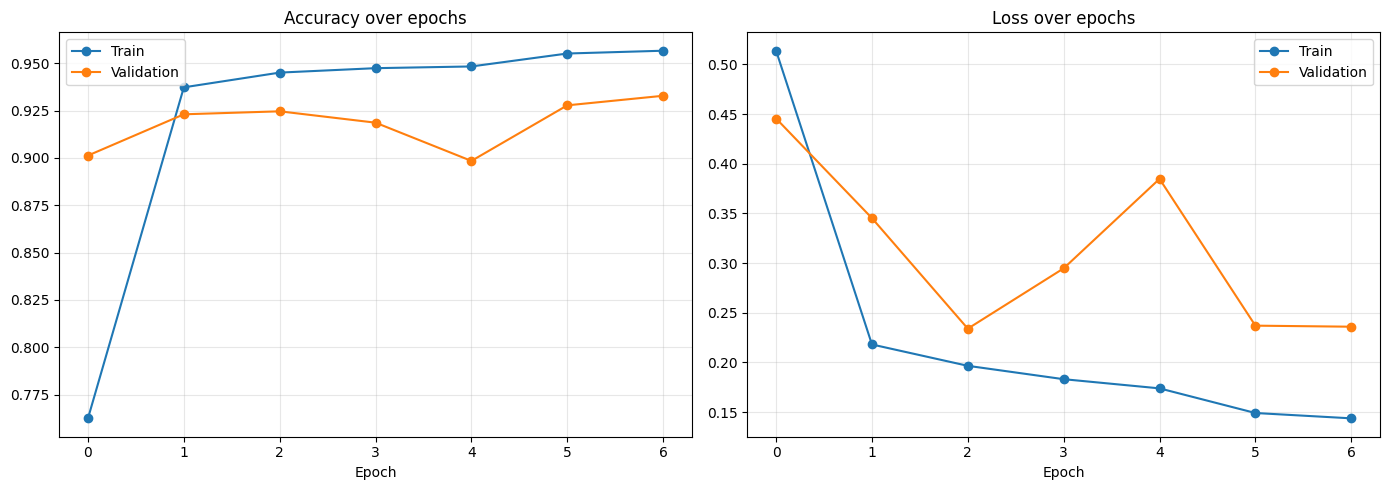

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a_, k, t in [(ax[0], "accuracy", "Accuracy"), (ax[1], "loss", "Loss")]:
    a_.plot(history.history[k], marker="o", label="Train")
    a_.plot(history.history["val_" + k], marker="o", label="Validation")
    a_.set_title(t + " over epochs"); a_.set_xlabel("Epoch"); a_.legend(); a_.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Insight:** Training accuracy rose quickly from 76% to about 96% and training loss fell steadily from 0.51 to 0.14, so the model learned the task within a few epochs. Validation accuracy stayed between 90% and 93%, and validation loss was lowest at epoch 3 (0.234), with a temporary rise at epoch 5 (0.385) before settling back to about 0.24. The gap between training and validation is small and does not widen over time, so there is no sign of serious overfitting. The dips in validation are probably down to the small validation set, where a few unusual patients can move the score. Early stopping ended training after epoch 7 and restored the epoch-3 weights, which had the lowest validation loss. Training stops earlier whenever early stopping decides more epochs aren’t helping. Stopping early also guards against overfitting, since the model doesn’t get time to memorise the training images.

# ***Test set evaluation***

In [23]:
va_gen = make_gen(final_va)
va_prob = model.predict(va_gen, verbose=0).ravel()   # validation probabilities (Parasitized = 1)
va_true = va_gen.classes

# 1) Show the trade-off first, so the target is chosen from evidence
print("Validation trade-off (nothing here uses the test set):")
for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01]:
    m_ = metrics_at(va_true, va_prob, t)
    print(f"  thr {t:.2f} | sens {m_['sensitivity']:.3f} | spec {m_['specificity']:.3f} | acc {m_['accuracy']:.3f}")

# 2) Choose the threshold: the highest specificity that still reaches the target sensitivity
TARGET_SENS = 0.90                                  # <- set this after reading the table above
thr_grid = np.linspace(0.01, 0.99, 99)              # wider grid than before (was 0.05-0.95)
best_thr, best_spec = 0.5, -1
for t in thr_grid:
    m_ = metrics_at(va_true, va_prob, t)
    if m_["sensitivity"] >= TARGET_SENS and m_["specificity"] > best_spec:
        best_thr, best_spec = t, m_["specificity"]

if best_spec < 0:
    print(f"\nTarget sensitivity {TARGET_SENS} not reachable on validation; keeping threshold 0.50")
    best_thr = 0.5
print(f"\nChosen threshold: {best_thr:.2f}  (target sensitivity {TARGET_SENS})")

# 3) Report validation at 0.50 and, if different, at the chosen threshold
print("Validation @0.50:", {k: round(float(v), 4) for k, v in metrics_at(va_true, va_prob, 0.5).items()})
if abs(best_thr - 0.5) > 1e-9:
    print(f"Validation @{best_thr:.2f}:", {k: round(float(v), 4) for k, v in metrics_at(va_true, va_prob, best_thr).items()})

Found 3169 validated image filenames belonging to 2 classes.
Validation trade-off (nothing here uses the test set):
  thr 0.50 | sens 0.863 | spec 0.973 | acc 0.925
  thr 0.40 | sens 0.875 | spec 0.967 | acc 0.927
  thr 0.30 | sens 0.886 | spec 0.958 | acc 0.926
  thr 0.20 | sens 0.899 | spec 0.940 | acc 0.922
  thr 0.10 | sens 0.927 | spec 0.886 | acc 0.904
  thr 0.05 | sens 0.951 | spec 0.768 | acc 0.848
  thr 0.02 | sens 0.973 | spec 0.423 | acc 0.664
  thr 0.01 | sens 0.991 | spec 0.130 | acc 0.507

Chosen threshold: 0.19  (target sensitivity 0.9)
Validation @0.50: {'accuracy': 0.9246, 'sensitivity': 0.863, 'specificity': 0.9725, 'precision': 0.9607, 'f1': 0.9092, 'auc': 0.9599}
Validation @0.19: {'accuracy': 0.9227, 'sensitivity': 0.9019, 'specificity': 0.9388, 'precision': 0.9199, 'f1': 0.9108, 'auc': 0.9599}


**Insight:** Two thresholds are reported. 0.50 is the standard default that treats both kinds of error equally. 0.19 was chosen on the validation set as the highest-specificity threshold that still reaches at least 90% sensitivity, because missing an infected cell is more costly than a false alarm that a technician can re-check.

In [24]:
# ---- Final test-set evaluation (30 held-out patients, never used for training, validation or tuning) ----
test_gen = make_gen(test_df)                           # plain generator: no augmentation, no shuffling
y_prob = model.predict(test_gen, verbose=0).ravel()    # predicted probability of Parasitized
y_true = test_gen.classes                              # true labels (0 = Uninfected, 1 = Parasitized)

# Always report 0.50; add the tuned threshold only if it differs
thresholds = [("threshold 0.50 (default)", 0.5)]
if abs(best_thr - 0.5) > 1e-9:
    thresholds.append((f"threshold {best_thr:.2f} (tuned on validation)", best_thr))

for name, thr in thresholds:
    res = metrics_at(y_true, y_prob, thr)
    tn, fp, fn, tp = confusion_matrix(y_true, (y_prob >= thr).astype(int), labels=[0, 1]).ravel()
    print(f"\n--- Test set, {name} ---")
    for k, v in res.items():
        print(f"{k:12s}: {v:.4f}")
    print(f"Confusion counts -> TP {tp} | FN (missed infections) {fn} | TN {tn} | FP (false alarms) {fp}")

print("\nClassification report @0.50:")
print(classification_report(y_true, (y_prob >= 0.5).astype(int), target_names=CLASSES))

Found 3451 validated image filenames belonging to 2 classes.

--- Test set, threshold 0.50 (default) ---
accuracy    : 0.9612
sensitivity : 0.9316
specificity : 0.9814
precision   : 0.9717
f1          : 0.9512
auc         : 0.9891
Confusion counts -> TP 1307 | FN (missed infections) 96 | TN 2010 | FP (false alarms) 38

--- Test set, threshold 0.19 (tuned on validation) ---
accuracy    : 0.9528
sensitivity : 0.9601
specificity : 0.9478
precision   : 0.9264
f1          : 0.9429
auc         : 0.9891
Confusion counts -> TP 1347 | FN (missed infections) 56 | TN 1941 | FP (false alarms) 107

Classification report @0.50:
              precision    recall  f1-score   support

  Uninfected       0.95      0.98      0.97      2048
 Parasitized       0.97      0.93      0.95      1403

    accuracy                           0.96      3451
   macro avg       0.96      0.96      0.96      3451
weighted avg       0.96      0.96      0.96      3451



# ***Confusion matrix + ROC curve***

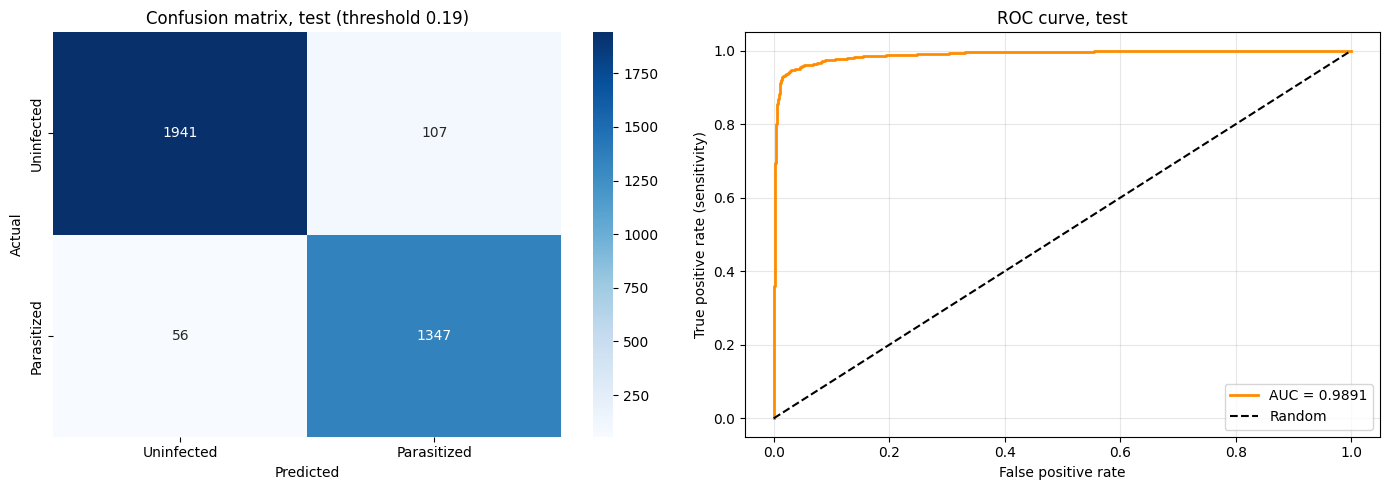

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix at the chosen threshold (best_thr is 0.50 if tuning did not change it)
cm = confusion_matrix(y_true, (y_prob >= best_thr).astype(int), labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
ax[0].set_title(f"Confusion matrix, test (threshold {best_thr:.2f})")

# ROC curve (does not depend on the threshold)
fpr, tpr, _ = roc_curve(y_true, y_prob)
ax[1].plot(fpr, tpr, lw=2, color="darkorange", label=f"AUC = {roc_auc_score(y_true, y_prob):.4f}")
ax[1].plot([0, 1], [0, 1], "k--", label="Random")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate (sensitivity)")
ax[1].set_title("ROC curve, test"); ax[1].legend(loc="lower right"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

# ***Save the model***

In [27]:
import json
model.save("/content/malaria_cnn.keras")
model.save("/content/malaria_cnn.h5")
with open("/content/model_config.json", "w") as f:
    json.dump({"threshold": float(best_thr), "classes": CLASSES,
               "positive_class": "Parasitized", "img_size": list(IMG_SIZE),
               "rescale": "1/255"}, f, indent=2)
from google.colab import files
files.download("/content/malaria_cnn.h5")
files.download("/content/model_config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>